<a href="https://colab.research.google.com/github/JJAMES02814199808/mlb-operations-pipeline/blob/main/Evaluating_Team_Run_Expectations_An_End_to_End_SQL_%26_Predictive_Modeling_Pipeline_in_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Power or Pitching? Analyzing MLB Wins through Home Runs and Net Run Production

By: Jahard James

Project goal: End-to-end SQL/Python data pipeline and linear regression model to evaluate team wins based off of key metrics

In [1]:
#installing pybaseball
!pip install pybaseball

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 41.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pybaseball]


#SQL DATA EXTRACTION

In [2]:
#import libraries
import sqlite3
import pandas as pd
from pybaseball import lahman

In [3]:

#  Direct raw CSV URL from the updated active repository
url = "https://storage.googleapis.com/trilogy_public_models/duckdb/lahman/Teams.csv"


In [4]:
teams_df = pd.read_csv(url)
print(teams_df.head())

   yearID lgID teamID franchID divID  Rank   G  Ghome   W   L  ...    DP  \
0    1871  NaN    BS1      BNA   NaN     3  31    NaN  20  10  ...  24.0   
1    1871  NaN    CH1      CNA   NaN     2  28    NaN  19   9  ...  16.0   
2    1871  NaN    CL1      CFC   NaN     8  29    NaN  10  19  ...  15.0   
3    1871  NaN    FW1      KEK   NaN     7  19    NaN   7  12  ...   8.0   
4    1871  NaN    NY2      NNA   NaN     5  33    NaN  16  17  ...  14.0   

      FP                     name                          park  attendance  \
0  0.834     Boston Red Stockings           South End Grounds I         NaN   
1  0.829  Chicago White Stockings       Union Base-Ball Grounds         NaN   
2  0.818   Cleveland Forest Citys  National Association Grounds         NaN   
3  0.803     Fort Wayne Kekiongas                Hamilton Field         NaN   
4  0.840         New York Mutuals      Union Grounds (Brooklyn)         NaN   

     BPF    PPF  teamIDBR  teamIDlahman45  teamIDretro  
0  103.0   

In [5]:
#connect sqlite3 to spin up in memory
conn=sqlite3.connect(":memory:")

In [6]:
teams_df.to_sql('teams',conn,index=False,if_exists="replace")

3614

##Total At-Bats

In [9]:


#Query for total team at bats

query= """
WITH teamAtBats AS (
     SELECT yearID, teamID,
     Max(NAME) AS team_name,
     SUM(AB) AS total_at_bats
     FROM Teams
     WHERE yearID >= 2010
     GROUP BY yearID,teamID
)

SELECT yearID,team_name,total_at_bats
FROM teamAtBats
ORDER BY total_at_bats DESC
LIMIT 5;
"""
Results = pd.read_sql(query, conn)
print(Results.head())
#

   yearID             team_name  total_at_bats
0    2019        Boston Red Sox         5770.0
1    2013        Detroit Tigers         5735.0
2    2019       Minnesota Twins         5732.0
3    2011        Boston Red Sox         5710.0
4    2013  Arizona Diamondbacks         5676.0


##Wins vs. Historical Franchise Average Wins

In [8]:

# Query to compare the team wins in the year 2023 to the teams historical average wins.
query= """
SELECT t1.yearID AS current_year,
t1.teamID,
t1.name AS team_name,
t1.W AS current_wins,
AVG(t2.W) AS historical_wins
FROM Teams t1
JOIN Teams t2 ON t1.teamID = t2.teamID
WHERE t1.yearID= 2023
GROUP BY t1.yearID, t1.teamID, t1.name, t1.W
ORDER BY current_wins DESC
LIMIT 5;
"""
Results=pd.read_sql(query,conn)
print(Results.head())

   current_year teamID            team_name  current_wins  historical_wins
0          2023    ATL       Atlanta Braves           104        82.100000
1          2023    BAL    Baltimore Orioles           101        79.625000
2          2023    LAN  Los Angeles Dodgers           100        86.779412
3          2023    TBA       Tampa Bay Rays            99        77.428571
4          2023    MIL    Milwaukee Brewers            92        78.750000


## TOP HOME RUN GENERATING TEAMS


In [10]:
#looking to locate top home run generating teams partitioned by year

query = """
SELECT
  yearID,
  teamID,
  name AS team_name,
  HR AS home_runs,
  -- ranking teams by run scored within each specific year
  RANK() OVER (PARTITION BY yearID ORDER BY HR DESC) AS HR_rank
FROM Teams
WHERE yearID >= 2015
ORDER BY yearID DESC, HR_rank ASC
LIMIT 10;
"""
Results=pd.read_sql(query,conn)
print(Results.head(10))

   yearID teamID                      team_name  home_runs  HR_rank
0    2025    NYA               New York Yankees      274.0        1
1    2025    LAN            Los Angeles Dodgers      244.0        2
2    2025    SEA               Seattle Mariners      238.0        3
3    2025    LAA  Los Angeles Angels of Anaheim      226.0        4
4    2025    NYN                  New York Mets      224.0        5
5    2025    CHN                   Chicago Cubs      223.0        6
6    2025    ATH                      Athletics      219.0        7
7    2025    ARI           Arizona Diamondbacks      214.0        8
8    2025    PHI          Philadelphia Phillies      212.0        9
9    2025    DET                 Detroit Tigers      198.0       10


#BRINGING METRICS TOGETHER

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

ML_query= """
   WITH TeamOffense AS (
    SELECT
        yearID,
        teamID,
        AB AS at_bats,
        name,
        HR,
        W,
        RANK() OVER (PARTITION BY yearID ORDER BY HR DESC) as hr_rank
    FROM Teams
    WHERE yearID >= 2010
)
SELECT  name AS team_name, hr_rank,HR, at_bats, w
FROM TeamOffense
WHERE W IS NOT NULL
ORDER BY W DESC;
"""

Results=pd.read_sql(ML_query,conn)
print(Results.head(15))

                team_name  hr_rank     HR  at_bats    W
0     Los Angeles Dodgers        5  212.0   5526.0  111
1          Boston Red Sox        9  208.0   5623.0  108
2          Houston Astros        3  288.0   5613.0  107
3    San Francisco Giants        2  241.0   5462.0  107
4     Los Angeles Dodgers        4  279.0   5493.0  106
5     Los Angeles Dodgers        4  237.0   5445.0  106
6          Houston Astros        4  214.0   5409.0  106
7     Los Angeles Dodgers       11  221.0   5408.0  104
8          Atlanta Braves        1  307.0   5597.0  104
9            Chicago Cubs       13  199.0   5503.0  103
10         Houston Astros       10  205.0   5453.0  103
11       New York Yankees        2  306.0   5583.0  103
12  Philadelphia Phillies       18  153.0   5579.0  102
13      Cleveland Indians       15  212.0   5511.0  102
14         Houston Astros        2  238.0   5611.0  101


MACHINE LEARNING EXTRACTED DATA

In [12]:
df_mL=pd.read_sql(ML_query,conn)
print(df_mL.head())


              team_name  hr_rank     HR  at_bats    W
0   Los Angeles Dodgers        5  212.0   5526.0  111
1        Boston Red Sox        9  208.0   5623.0  108
2        Houston Astros        3  288.0   5613.0  107
3  San Francisco Giants        2  241.0   5462.0  107
4   Los Angeles Dodgers        4  279.0   5493.0  106


## MACHINE LEARNING

In [13]:
#Pulling the home run, home run rank, and team wins columns
X=df_mL[['HR','hr_rank']]
y=df_mL['W']

In [14]:
# Setting X and y values for linear regression model
X=df_mL[['HR','hr_rank']]
y=df_mL['W']

In [15]:
Model= LinearRegression()
Model.fit(X,y)

LinearRegression()

#Linear Regression correlation

The graph below shows a positive correlation between home runs and team wins. Home runs is a reasonable metric to estimate runs, every home run always produces a run. The more runs scored throughout a season is likely to produce wins. This proves statistically that the more home runs a team can generate, the more wins they can likely generate, with a few outliers that show otherwise. The outliers highlight other unique metrics, when analyzed together, produce different outcomes in terms of wins. For organization, I will analyze the outliers in terms of the types of outlier teams, such as: High home runs/low win teams, Low home runs/ high wins teams.

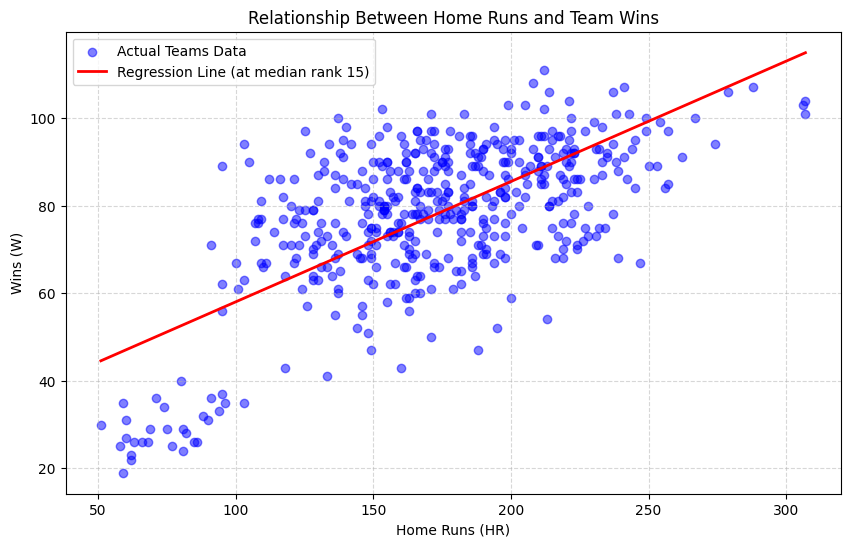

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Scatter plot of actual Home Runs vs. Wins
plt.figure(figsize=(10, 6))
plt.scatter(df_mL['HR'], df_mL['W'], color='blue', alpha=0.5, label='Actual Teams Data')
plt.savefig('hr_wins_regression.png', dpi=300, bbox_inches='tight')

# Since Model was trained on [HR, hr_rank], we can show a simplified 1D regression trend
# by fixing hr_rank at its median value to plot the predicted wins as a function of HR.
hr_range = np.linspace(df_mL['HR'].min(), df_mL['HR'].max(), 100)
median_hr_rank = np.full_like(hr_range, df_mL['hr_rank'].median())

# Wrap predictions in a DataFrame with matching column names to suppress feature name warnings
X_plot = pd.DataFrame({
    'HR': hr_range,
    'hr_rank': median_hr_rank
})
y_pred = Model.predict(X_plot)

# Plot the regression line
plt.plot(hr_range, y_pred, color='red', linewidth=2, label=f'Regression Line (at median rank {int(df_mL["hr_rank"].median())})')

# Customize plot
plt.title('Relationship Between Home Runs and Team Wins')
plt.xlabel('Home Runs (HR)')
plt.ylabel('Wins (W)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('hr_wins_regression_outliers.png', dpi=300, bbox_inches='tight')
plt.show()

#Analyzing Outliers

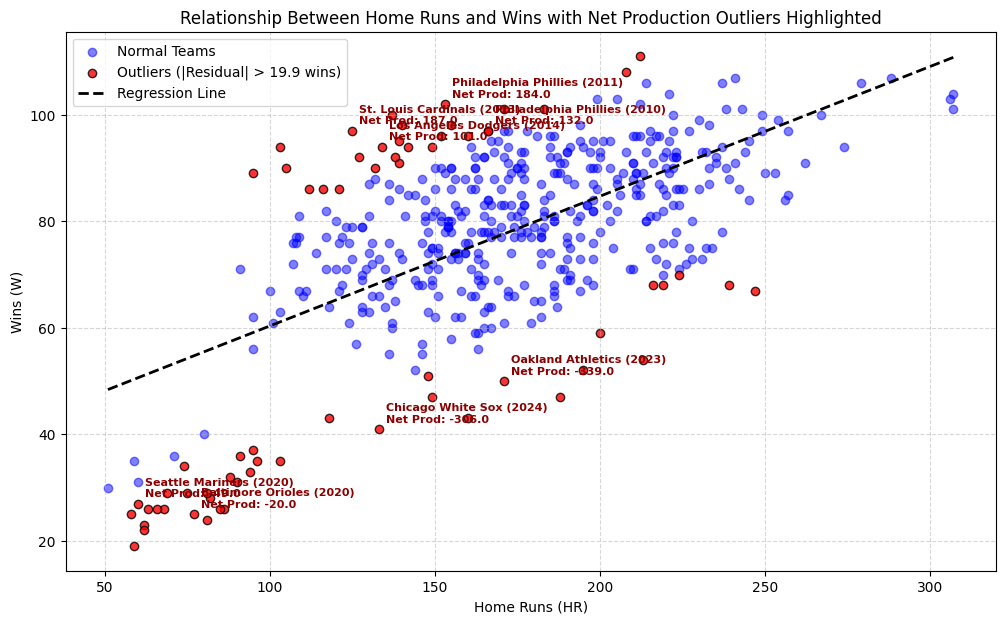

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# 1. Extracting data with R (runs scored), RA (runs allowed), and yearID to calculate Net_Production
query_outliers = """
WITH TeamOffense AS (
    SELECT
        yearID,
        teamID,
        name,
        HR,
        R,
        RA,
        W,
        RANK() OVER (PARTITION BY yearID ORDER BY HR DESC) as hr_rank
    FROM Teams
    WHERE yearID >= 2010
)
SELECT yearID, name, HR, R, RA, W, hr_rank
FROM TeamOffense
WHERE W IS NOT NULL AND R IS NOT NULL AND RA IS NOT NULL;
"""

df_outliers = pd.read_sql(query_outliers, conn)
df_outliers['Net_Production'] = df_outliers['R'] - df_outliers['RA']

# 2. Fit a Simple Linear Regression: HR predicting Wins (W)
X_lr = df_outliers[['HR']]
y_lr = df_outliers['W']
model_lr = LinearRegression()
model_lr.fit(X_lr, y_lr)

# Calculate predicted Wins and the residual (difference between actual and predicted)
df_outliers['Predicted_W'] = model_lr.predict(X_lr)
df_outliers['Residual'] = df_outliers['W'] - df_outliers['Predicted_W']

# Define Outliers: Teams with high residuals
threshold = 1.5 * df_outliers['Residual'].std()
is_outlier = df_outliers['Residual'].abs() > threshold

# Split into normal teams and outliers
normal_teams = df_outliers[~is_outlier]
outliers = df_outliers[is_outlier]

# 3. Plotting the results
plt.figure(figsize=(12, 7))

# Plot normal teams
plt.scatter(normal_teams['HR'], normal_teams['W'], color='blue', alpha=0.5, label='Normal Teams')

# Plot outliers in red
plt.scatter(outliers['HR'], outliers['W'], color='red', alpha=0.8, edgecolors='black', label=f'Outliers (|Residual| > {threshold:.1f} wins)')

# Plot regression line using DataFrame to match feature names
hr_line = np.linspace(df_outliers['HR'].min(), df_outliers['HR'].max(), 100).reshape(-1, 1)
X_line_df = pd.DataFrame(hr_line, columns=['HR'])
plt.plot(hr_line, model_lr.predict(X_line_df), color='black', linestyle='--', linewidth=2, label='Regression Line')

# outlier teams for context
for idx, row in outliers.sample(min(8, len(outliers)), random_state=42).iterrows():
    plt.annotate(f"{row['name']} ({row['yearID']})\nNet Prod: {row['Net_Production']}",
                 (row['HR'], row['W']),
                 textcoords="offset points",
                 xytext=(5,5),
                 ha='left', fontsize=8, color='darkred', weight='bold')

plt.title('Relationship Between Home Runs and Wins with Net Production Outliers Highlighted')
plt.xlabel('Home Runs (HR)')
plt.ylabel('Wins (W)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#Notable insights from outliers



### Notable Insights from the Outlier Analysis

Analyzing the linear regression model that predicts Wins ($W$) using Home Runs ($HR$) reveals key takeaways about baseball dynamics:

1. **Home Runs as a Strong Indicator**: The upward-sloping dashed regression line demonstrates a clear, positive correlation between a team's home run output and its overall success. Generating home runs inherently guarantees runs scored, which serves as a primary foundation for securing wins.
2. **The Impact of Net Production ($R - RA$)**: The outliers (highlighted in red) demonstrate that home runs alone do not guarantee a team's final standing. Teams that fall far above or below the regression line are heavily influenced by their **Net Production** (Runs Scored minus Runs Allowed):
   - **Over-performing Outliers**: Teams like the **2011 Philadelphia Phillies (Net Prod: 184)** and **2013 St. Louis Cardinals (Net Prod: 187)** won significantly more games than their home run metrics alone would predict. This is driven by exceptional pitching/defense (minimizing Runs Allowed) and efficient situational hitting.
   - **Under-performing Outliers**: Conversely, teams like the **2024 Chicago White Sox (Net Prod: -306)** and **2023 Oakland Athletics (Net Prod: -339)** finished far below the regression line. Despite any home runs hit, their extremely negative net production (primarily due to giving up far more runs than they scored) dragged down their win totals, emphasizing that runs allowed are just as crucial to manage as runs scored.